In [2]:

from pathlib import Path
from PIL import Image, ImageOps, ImageFilter
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

DATASET_ROOT = Path(
    r"C:\Users\SWARA\Documents\Handwriting Analysis\dataset"
)

RAW_DIR = DATASET_ROOT
METADATA_CSV = DATASET_ROOT / "metadata" / "dataset_metadata.csv"

PROCESSED_ROOT = DATASET_ROOT / "processed"
PAGE_DIR = PROCESSED_ROOT / "pages"
BINARY_DIR = PROCESSED_ROOT / "binary_preview"
PATCH_DIR = PROCESSED_ROOT / "efficientnet_patches"
PATCH_224_DIR = PROCESSED_ROOT / "efficientnet_patches_224"

for directory in [
    PAGE_DIR, BINARY_DIR, PATCH_DIR, PATCH_224_DIR
]:
    directory.mkdir(parents=True, exist_ok=True)

PATCH_SIZE = 640
STRIDE = 480
MODEL_SIZE = 224

# Keep False for the first run.
# Set True only if the already extracted patches need the
# exact same enhancement pipeline applied a second time.
REPROCESS_PATCHES = False

# If True, output patches are processed again by the same function.
# Avoid enabling this without comparing the visual results.
print("Processing configuration loaded.")

Processing configuration loaded.


In [3]:

def process_handwriting_image(pil_image):
    """
    Input: PIL image
    Output:
      enhanced_gray: enhanced grayscale image for model input
      binary_image: diagnostic thresholded image for visual inspection
    """

    # Respect camera/scanner orientation metadata
    image = ImageOps.exif_transpose(pil_image).convert("RGB")
    rgb = np.array(image)

    # Grayscale conversion
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)

    # Gentle denoising; keep handwriting strokes intact
    denoised = cv2.fastNlMeansDenoising(
        gray, None, h=3, templateWindowSize=7, searchWindowSize=21
    )

    # Local contrast enhancement
    clahe = cv2.createCLAHE(
        clipLimit=1.5,
        tileGridSize=(8, 8)
    )
    enhanced = clahe.apply(denoised)

    # Mild unsharp masking
    blurred = cv2.GaussianBlur(enhanced, (0, 0), sigmaX=1.0)
    sharpened = cv2.addWeighted(
        enhanced, 1.20, blurred, -0.20, 0
    )

    # Binary output is for diagnostics/segmentation only.
    # Do not use it as the only model input by default.
    binary = cv2.adaptiveThreshold(
        sharpened,
        255,
        cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
        cv2.THRESH_BINARY,
        31,
        11
    )

    return (
        Image.fromarray(sharpened),
        Image.fromarray(binary)
    )

In [ ]:

metadata_df = pd.read_csv(METADATA_CSV)
valid_metadata = metadata_df[metadata_df["is_valid"] == True].copy()

def safe_id(relative_path):
    rel = str(relative_path).replace("\\", "/")
    stem = Path(rel).stem
    digest = hashlib.sha1(rel.encode("utf-8")).hexdigest()[:10]
    return f"{stem}_{digest}"

page_records = []

for _, row in tqdm(
    valid_metadata.iterrows(),
    total=len(valid_metadata),
    desc="Processing pages"
):
    source_path = Path(row["absolute_path"])
    page_id = safe_id(row["relative_path"])

    output_page = PAGE_DIR / f"{page_id}.png"
    output_binary = BINARY_DIR / f"{page_id}_binary.png"

    try:
        with Image.open(source_path) as im:
            enhanced, binary = process_handwriting_image(im)

        enhanced.save(output_page)
        binary.save(output_binary)

        page_records.append({
            "page_id": page_id,
            "filename": source_path.name,
            "relative_path": row["relative_path"],
            "source_path": str(source_path),
            "processed_path": str(output_page),
            "binary_path": str(output_binary),
            "width": enhanced.width,
            "height": enhanced.height,
            "status": "success",
            "error": None
        })

    except Exception as e:
        page_records.append({
            "page_id": page_id,
            "filename": source_path.name,
            "relative_path": row["relative_path"],
            "source_path": str(source_path),
            "processed_path": None,
            "binary_path": None,
            "width": None,
            "height": None,
            "status": "failed",
            "error": str(e)
        })

processed_pages_df = pd.DataFrame(page_records)
processed_pages_df.to_csv(
    PROCESSED_ROOT / "processed_pages_metadata.csv",
    index=False
)

print(processed_pages_df["status"].value_counts())
display(processed_pages_df.head())

Processing pages:   0%|          | 0/780 [00:00<?, ?it/s]

In [ ]:

successful_pages = processed_pages_df[
    processed_pages_df["status"] == "success"
]

sample = successful_pages.sample(
    min(3, len(successful_pages)),
    random_state=42
)

for _, row in sample.iterrows():
    with Image.open(row["source_path"]) as im:
        original = ImageOps.exif_transpose(im).convert("RGB")

    with Image.open(row["processed_path"]) as im:
        enhanced = im.copy()

    with Image.open(row["binary_path"]) as im:
        binary = im.copy()

    fig, axes = plt.subplots(1, 3, figsize=(16, 6))

    axes[0].imshow(original)
    axes[0].set_title("Original")

    axes[1].imshow(enhanced, cmap="gray")
    axes[1].set_title("Enhanced grayscale")

    axes[2].imshow(binary, cmap="gray")
    axes[2].set_title("Binary diagnostic")

    for ax in axes:
        ax.axis("off")

    plt.suptitle(row["filename"])
    plt.tight_layout()
    plt.show()

In [ ]:

def extract_overlapping_patches(image, patch_size=640, stride=480):
    image = image.convert("L")
    width, height = image.size

    # Pad small pages to at least one complete patch
    padded_width = max(width, patch_size)
    padded_height = max(height, patch_size)

    padded = Image.new(
        "L",
        (padded_width, padded_height),
        color=255
    )
    padded.paste(image, (0, 0))

    # Always include the final edge position
    x_positions = list(range(0, padded_width - patch_size + 1, stride))
    y_positions = list(range(0, padded_height - patch_size + 1, stride))

    last_x = padded_width - patch_size
    last_y = padded_height - patch_size

    if not x_positions or x_positions[-1] != last_x:
        x_positions.append(last_x)

    if not y_positions or y_positions[-1] != last_y:
        y_positions.append(last_y)

    patches = []

    for y in sorted(set(y_positions)):
        for x in sorted(set(x_positions)):
            patch = padded.crop((
                x, y, x + patch_size, y + patch_size
            ))

            patches.append({
                "image": patch,
                "x": x,
                "y": y,
                "source_width": width,
                "source_height": height
            })

    return patches

In [ ]:

patch_records = []

for _, row in tqdm(
    successful_pages.iterrows(),
    total=len(successful_pages),
    desc="Extracting patches"
):
    page_id = row["page_id"]

    with Image.open(row["processed_path"]) as im:
        page_image = im.convert("L")

    patches = extract_overlapping_patches(
        page_image,
        patch_size=PATCH_SIZE,
        stride=STRIDE
    )

    for patch_index, item in enumerate(patches):
        patch = item["image"]

        if REPROCESS_PATCHES:
            patch, _ = process_handwriting_image(patch)

        patch_filename = f"{page_id}_patch_{patch_index:04d}.png"
        patch_path = PATCH_DIR / patch_filename

        patch.save(patch_path)

        patch_records.append({
            "page_id": page_id,
            "filename": row["filename"],
            "source_path": row["source_path"],
            "processed_page_path": row["processed_path"],
            "patch_index": patch_index,
            "x": item["x"],
            "y": item["y"],
            "source_width": item["source_width"],
            "source_height": item["source_height"],
            "patch_size": PATCH_SIZE,
            "stride": STRIDE,
            "patch_path": str(patch_path),
            "patch_reprocessed": REPROCESS_PATCHES
        })

patch_metadata_df = pd.DataFrame(patch_records)

patch_metadata_df.to_csv(
    PROCESSED_ROOT / "patch_metadata.csv",
    index=False
)

print("Total patches:", len(patch_metadata_df))
print("Unique source pages:", patch_metadata_df["source_path"].nunique())
display(patch_metadata_df.head())

Total patches: 12851
Unique source pages: 780


,page_id,filename,source_path,processed_page_path,patch_index,x,y,source_width,source_height,patch_size,stride,patch_path,patch_reprocessed
0,page001_8795ef1ce0,page001.jpg,C:\Users\SWARA\Documents\Handwriting Analysis\...,C:\Users\SWARA\Documents\Handwriting Analysis\...,0,0,0,1898,2628,640,480,C:\Users\SWARA\Documents\Handwriting Analysis\...,False
1,page001_8795ef1ce0,page001.jpg,C:\Users\SWARA\Documents\Handwriting Analysis\...,C:\Users\SWARA\Documents\Handwriting Analysis\...,1,480,0,1898,2628,640,480,C:\Users\SWARA\Documents\Handwriting Analysis\...,False
2,page001_8795ef1ce0,page001.jpg,C:\Users\SWARA\Documents\Handwriting Analysis\...,C:\Users\SWARA\Documents\Handwriting Analysis\...,2,960,0,1898,2628,640,480,C:\Users\SWARA\Documents\Handwriting Analysis\...,False
3,page001_8795ef1ce0,page001.jpg,C:\Users\SWARA\Documents\Handwriting Analysis\...,C:\Users\SWARA\Documents\Handwriting Analysis\...,3,1258,0,1898,2628,640,480,C:\Users\SWARA\Documents\Handwriting Analysis\...,False
4,page001_8795ef1ce0,page001.jpg,C:\Users\SWARA\Documents\Handwriting Analysis\...,C:\Users\SWARA\Documents\Handwriting Analysis\...,4,0,480,1898,2628,640,480,C:\Users\SWARA\Documents\Handwriting Analysis\...,False


In [ ]:

resize_records = []

for _, row in tqdm(
    patch_metadata_df.iterrows(),
    total=len(patch_metadata_df),
    desc="Resizing patches"
):
    input_path = Path(row["patch_path"])
    output_path = PATCH_224_DIR / input_path.name

    try:
        with Image.open(input_path) as im:
            resized = im.convert("RGB").resize(
                (MODEL_SIZE, MODEL_SIZE),
                Image.Resampling.LANCZOS
            )
            resized.save(output_path)

        resize_records.append({
            **row.to_dict(),
            "patch_path_224": str(output_path),
            "target_size": MODEL_SIZE,
            "resize_status": "success"
        })

    except Exception as e:
        resize_records.append({
            **row.to_dict(),
            "patch_path_224": None,
            "target_size": MODEL_SIZE,
            "resize_status": "failed",
            "resize_error": str(e)
        })

patch_metadata_224 = pd.DataFrame(resize_records)

patch_metadata_224.to_csv(
    PROCESSED_ROOT / "patch_metadata_224.csv",
    index=False
)

print(patch_metadata_224["resize_status"].value_counts())
print("Metadata:", PROCESSED_ROOT / "patch_metadata_224.csv")

Resizing patches:   0%|          | 0/12851 [00:00<?, ?it/s]

resize_status
success    12851
Name: count, dtype: int64
Metadata: C:\Users\SWARA\Documents\Handwriting Analysis\dataset\processed\patch_metadata_224.csv


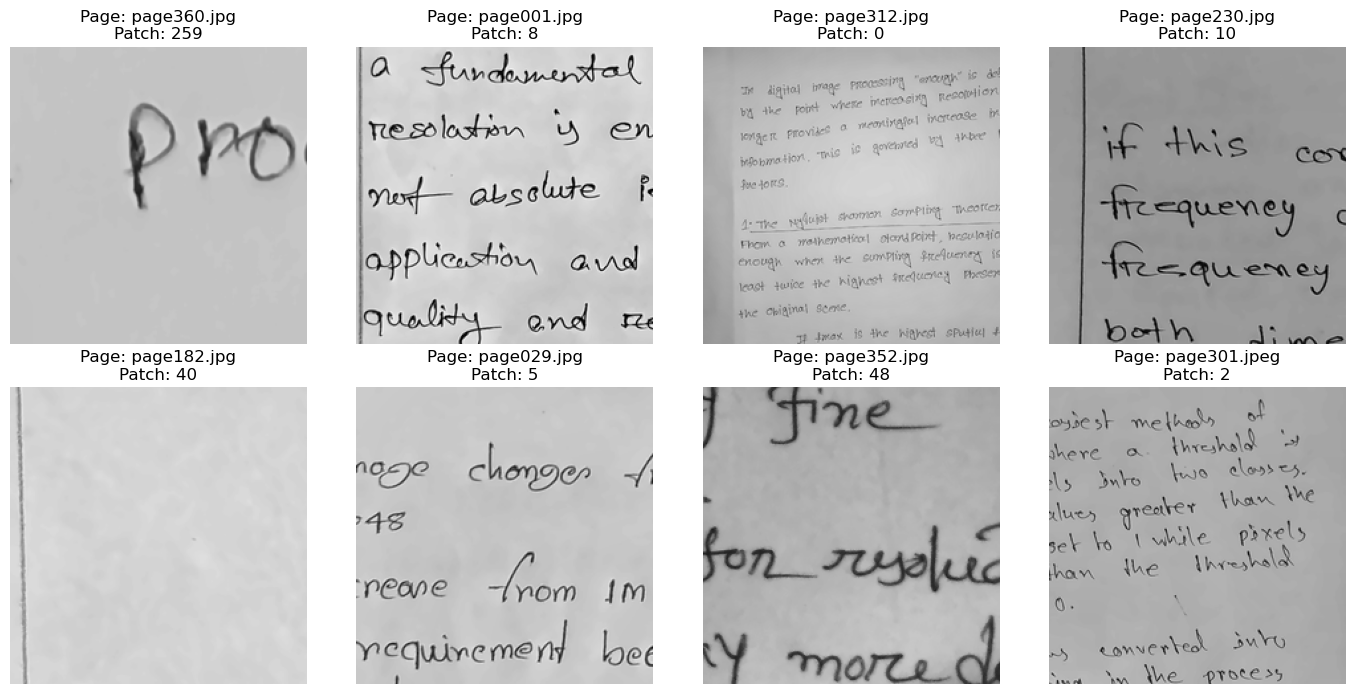

Final patches: 12851
Final patch size: 224 × 224


In [ ]:

final_patches = patch_metadata_224[
    patch_metadata_224["resize_status"] == "success"
]

sample = final_patches.sample(
    min(8, len(final_patches)),
    random_state=42
)

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
axes = axes.flatten()

for ax, (_, row) in zip(axes, sample.iterrows()):
    with Image.open(row["patch_path_224"]) as im:
        ax.imshow(im)

    ax.set_title(
        f"Page: {row['filename']}\nPatch: {row['patch_index']}"
    )
    ax.axis("off")

for ax in axes[len(sample):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Final patches:", len(final_patches))
print("Final patch size:", MODEL_SIZE, "×", MODEL_SIZE)